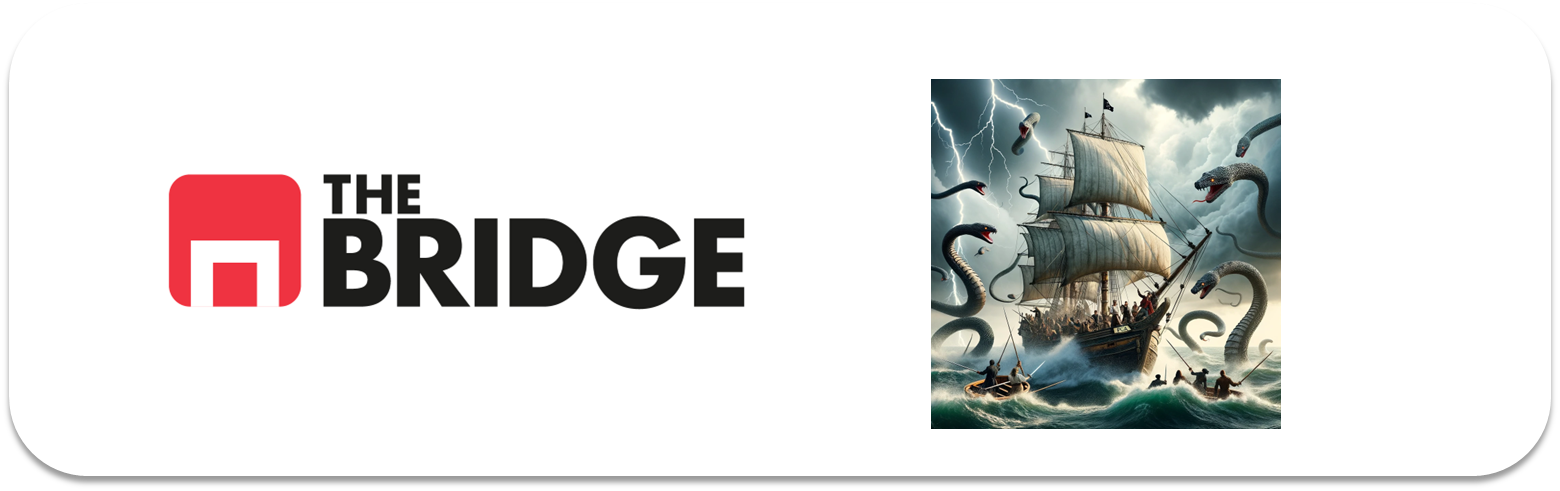

## Selección de Features: motivación y tipos

**MOTIVACIÓN**

$$*$$

¿Por qué sería necesario seleccionar características? Para algunos, esta idea puede parecer contraintuitiva, ya que a más datos, en teoría, más información.

Al empezar el bloque de No Supervisado ya vimos que existe lo que se denomina la "maldición de la dimensionalidad", que a veces puede quedarse en algo más etéreo o difícil de ver. Vayamos a varias razones muy prácticas por las cuales merece la pena seleccionar y descartar, o por lo menos priorizar, tus features:

1. Un tema de **rendimiento** (a veces menor, con datasets pequeños): a menos features, menos tiempo de procesado (en entrenamiento y en producción).

2. Un tema de ingeniería, **soporte y escalabilidad**: a menos features, los procesos de preparación, ETL y gestión son más manejables. Además, a menos features, en general, menos probabilidad de fallos en esos procesos como consecuencia de los datos (de nuevo, depende mucho de los datasets).

3. Un tema de **explicabilidad y atribución** (cada vez más necesario): con menos features, los modelos son más fáciles de atribuir (decidir qué features o combinaciones son las "importantes") y, en general, de explicar. [NOTA: Aquí los mecanismos que transforman las features para luego reducirlas, como la PCA, puntúan menos.]

4. Un tema de **robustez**: a menos features, menor probabilidad de que falten datos para alguna de ellas y de que el modelo falle en producción por esa falta de datos.

5. Un tema de **regularización**: menos features implica evitar que algunos algoritmos confundan el ruido de algunas de ellas con información y acaben sobreajustando. Ya sabes, le pones las cosas más difíciles al modelo -> lo haces más fuerte.

Finalmente, hay un tema adicional de **conocimiento de los datos** que no tiene que ver con la selección sino con el proceso de "seleccionar": te obliga a conocer tus datos (a mayor o menor nivel, dependiendo del tipo de selección). Este conocimiento siempre es bueno, ayuda a gestionar expectativas y a saber dónde atacar cuando surgen problemas o los resultados no son los esperados.

¿Hay que reducir siempre las features? No. De hecho, muchas veces ni pasarás por este paso (erróneamente). Analiza siempre tus features como si tuvieras que seleccionarlas. Toma notas de cuáles son más informativas, cuáles están más relacionadas, cuáles se podrían transformar, por supuesto cuáles son poco informativas, etc. Priorízalas y luego úsalas todas si tu tiempo y tus recursos lo permiten, para después hacer la selección. O no las uses todas y resérvate las menos prioritarias: si los resultados acompañan, las tendrás ahí para tiempos de necesidad.

**¿Y seleccionar mejora siempre el modelo?** Tampoco. Fíjate en que casi todas las razones anteriores tienen que ver con la simplicidad, el coste o la robustez, no con la métrica. Cuando tenemos pocas features y casi todas aportan algo, lo normal es que seleccionar cueste un poco de rendimiento a cambio de un modelo más simple, y nuestra tarea será decidir si ese compromiso compensa. Donde la selección sí marca la diferencia en la métrica es cuando hay features irrelevantes o ruido. Veremos ambos casos a lo largo de este notebook.

Ah, y las features cuyo valor no cambia o es diferente para cada instancia (features invariantes y features índice) puedes obviarlas para el modelo. Estas sí, aunque ojo con los índices para posteriores asignaciones e identificaciones.

**TIPOS y SUBTIPOS**

No es que existan formalmente unos tipos de selección de features, más bien hay mecánicas que varían según los datos de los que disponemos y de lo que queremos hacer con ellos y el nivel de profundidad del análisis. En esa línea distinguimos:

**A. Análisis "visual"**: Se apoya en medios visuales y numéricos (el que hemos empleado hasta ahora)  

**B. Análisis con métodos supervisados**: Se usan cuando tenemos un dataset con target y se apoyan en relaciones numéricas de las features con el target. Vamos a ver tres subtipos:  
    B.1 Filter: Selección mediante medidas matemáticas de relación (depende del tipo de target y del tipo de feature, categórica y numérica). Es la versión más numérica del tipo anterior.  
    B.2 Intrinsic: Selección mediante un modelo. Se crea un modelo sencillo que prediga la variable target y se seleccionan las features de mayor importancia para trabajar en modelados posteriores más complejos.  
    B.3 Wrapper: Selección mediante wrapper. Se crea un modelo con todas o con una única feature, se hace una selección o deselección hasta llegar a un punto de compromiso.  

**C. Análisis con métodos no supervisados**: Nos valen para cualquier tipo de dataset y son métodos basados en varianzas y covarianzas:  
    C.1 Umbral de Varianza: Se fija un umbral de varianza y se descartan aquellas variables que no lo alcanzan.  
    C.2 PCA: Ya la conoces de la unidad dedicada especialmente a ella.  

### **A. Análisis Visual**

Comenzamos repasando el método que hemos empleado en los modelados anteriores. Para ello vamos a usar dos datasets, el del Titanic y el de la calidad del vino, para ver los análisis con target categórico y con target numérico.

Consideraciones previas:
* El análisis visual no debería ser el único análisis pero también debería estar presente siempre que se pueda. Su ventaja subyacente es que obliga a "mirar" todas las features contra el target (caso de datasets supervisados). 
* Puede resultar inabordable si el número de features es muy alto, en cuyo caso la estrategia propuesta es reducir empleando alguna de las otras técnicas y analizar visualmente las dudosas (en los umbrales) y las finalmente seleccionadas. 

#### Target Categórico: Titanic

NOTA: En este notebook, y como excepción, dado el diferente tipo de elementos que se tratan iremos importando las librerías a medida que se necesiten, y es eso, una excepción :-)

In [1]:
import bootcampviztools as bt
import pandas as pd

In [2]:
df = pd.read_csv("../data/titanic.csv")
df

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,0,2,male,27.0,0,0,13.0000,S,Second,man,True,NaN,Southampton,no,True
887,1,1,female,19.0,0,0,30.0000,S,First,woman,False,B,Southampton,yes,True
888,0,3,female,NaN,1,2,23.4500,S,Third,woman,False,NaN,Southampton,no,False
889,1,1,male,26.0,0,0,30.0000,C,First,man,True,C,Cherbourg,yes,True


El target es "survived" y veremos el análisis contra una variable categórica ("who") y una numérica ("age"), empleando diferentes visualizaciones

In [3]:
target = "survived"
cat_col = "who"
num_col = "age"

IMPORTANTE: Durante todo este notebook vamos a usar todo el dataset que toque como train por simplicidad; recuerda que en tus modelos supervisados necesitarás crear un test.

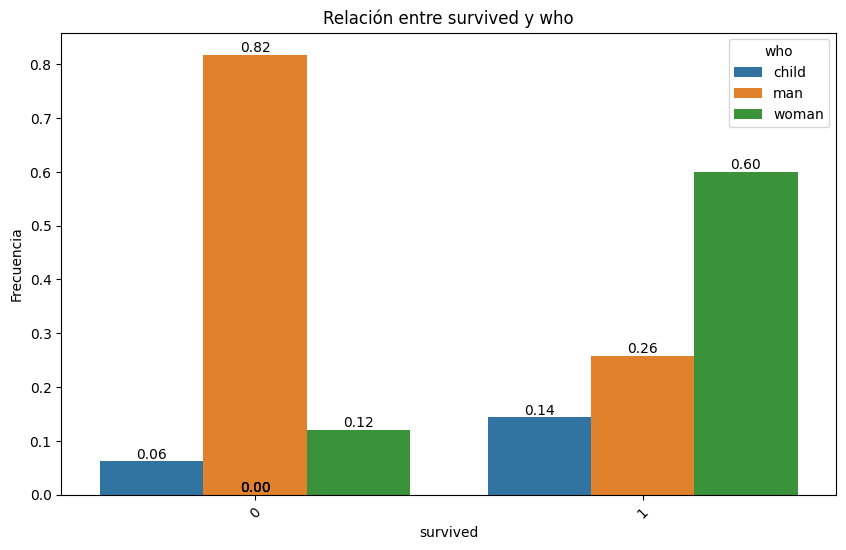

In [4]:
bt.plot_categorical_relationship_fin(df,target,cat_col,show_values= True, relative_freq= True)

En este caso nos fijamos en:
* Figuras diferentes
* Valores de distribución diferente para las mismas categorías en cada una de las categorías del target
En concreto, tiene distribuciones claramente diferentes para 0 y 1, con valores sensiblemente diferentes en algunas categorías de la feature analizada (la que no es target). Nos la quedamos como prioritaria.

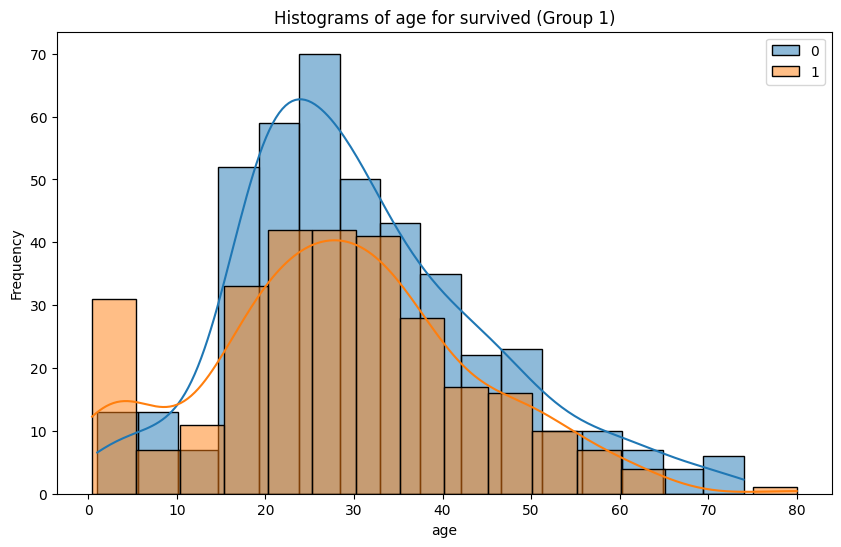

In [5]:
bt.plot_grouped_histograms(df,cat_col = target, num_col= num_col, group_size= 2)

* En estos casos nos fijamos en que las distribuciones no se superpongan completamente, que existan desplazamientos de una frente a la otra y que existan áreas donde predominen claramente una sobre la otra (en un target binario, en un multiclase tendríamos que comparar todas a la vez o de dos en dos).
* En concreto, aquí se ve una predominancia del 1 para edades bajas y del 0 para edades más altas. Eso le da cierto valor predictivo pero se superponen mucho las dos figuras. Sería una feature de segunda prioridad, pasando a primera si no hubiera otra numérica continua con esa categoría.

### Target Numérico: Calidad del Vino


En este caso tenemos un target numérico y vamos a ver cómo visualizarlo ante una variable categórica y cómo analizar con varias numéricas gracias a las correlaciones, que además nos permiten ver colinealidades posibles:

In [6]:
df_wines= pd.read_csv("../data/wines_dataset.csv", sep = "|")
df_wines

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,class
0,8.5,0.21,0.26,9.25,0.034,73.0,142.0,0.99450,3.05,0.37,11.4,6,white
1,8.3,0.16,0.37,7.90,0.025,38.0,107.0,0.99306,2.93,0.37,11.9,6,white
2,6.8,0.18,0.38,1.40,0.038,35.0,111.0,0.99180,3.32,0.59,11.2,7,white
3,6.1,0.26,0.25,2.90,0.047,289.0,440.0,0.99314,3.44,0.64,10.5,3,white
4,7.5,0.63,0.27,2.00,0.083,17.0,91.0,0.99616,3.26,0.58,9.8,6,red
...,...,...,...,...,...,...,...,...,...,...,...,...,...
6492,7.7,0.39,0.34,10.00,0.056,35.0,178.0,0.99740,3.26,0.60,10.2,5,white
6493,8.2,0.73,0.21,1.70,0.074,5.0,13.0,0.99680,3.20,0.52,9.5,5,red
6494,7.4,0.31,0.48,14.20,0.042,62.0,204.0,0.99830,3.06,0.59,9.4,5,white
6495,8.3,0.65,0.10,2.90,0.089,17.0,40.0,0.99803,3.29,0.55,9.5,5,red


In [7]:
target = "alcohol"
cat_col = "class"
num_col = "density"

Para el caso de la categórica, es similar a cuando el target es categórico y la feature numérica, pintamos las distribuciones de la numérica para cada uno de los valores de la categórica:

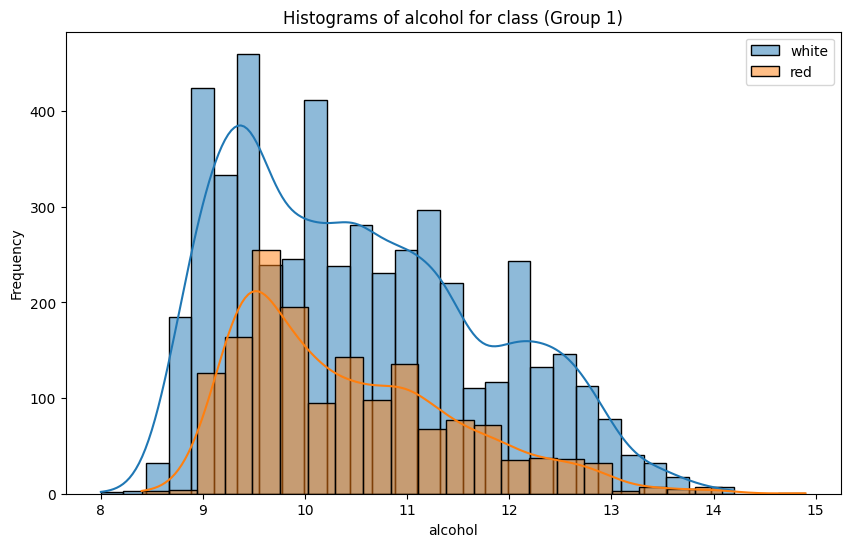

In [8]:
bt.plot_grouped_histograms(df_wines, cat_col = cat_col, num_col = target, group_size= df_wines[cat_col].nunique())

* Miramos los mismos elementos que antes: 
* Separación entre distribuciones, zonas dominadas, cruces de kde...
* En este caso hay una zona dominante de la clase white tanto para valores superiores como para valores inferiores; el resto es bastante similar. "Class" estaría entre una prioridad media y baja.

Para las numéricas, vemos las correlaciones (repetiremos en algún subtipo B) y luego la matriz de correlación a través del heatmap:

In [9]:
features_num = df_wines.columns.to_list()
features_num.remove("class")


In [10]:
import numpy as np

corr= df_wines[features_num].corr()
serie_corr = np.abs(corr[target])
serie_corr.sort_values(ascending = False)

alcohol                 1.000000
density                 0.686745
quality                 0.444319
residual sugar          0.359415
total sulfur dioxide    0.265740
chlorides               0.256916
free sulfur dioxide     0.179838
pH                      0.121248
fixed acidity           0.095452
volatile acidity        0.037640
citric acid             0.010493
sulphates               0.003029
Name: alcohol, dtype: float64

Estableceremos un punto de corte y nos quedaremos con las que superen ese punto de corte para luego compararlas en un heatmap:

In [11]:
r_minimo = 0.10
features_num_sel = serie_corr[serie_corr >= r_minimo].index.to_list()
features_num_sel

['residual sugar',
 'chlorides',
 'free sulfur dioxide',
 'total sulfur dioxide',
 'density',
 'pH',
 'alcohol',
 'quality']

<Axes: >

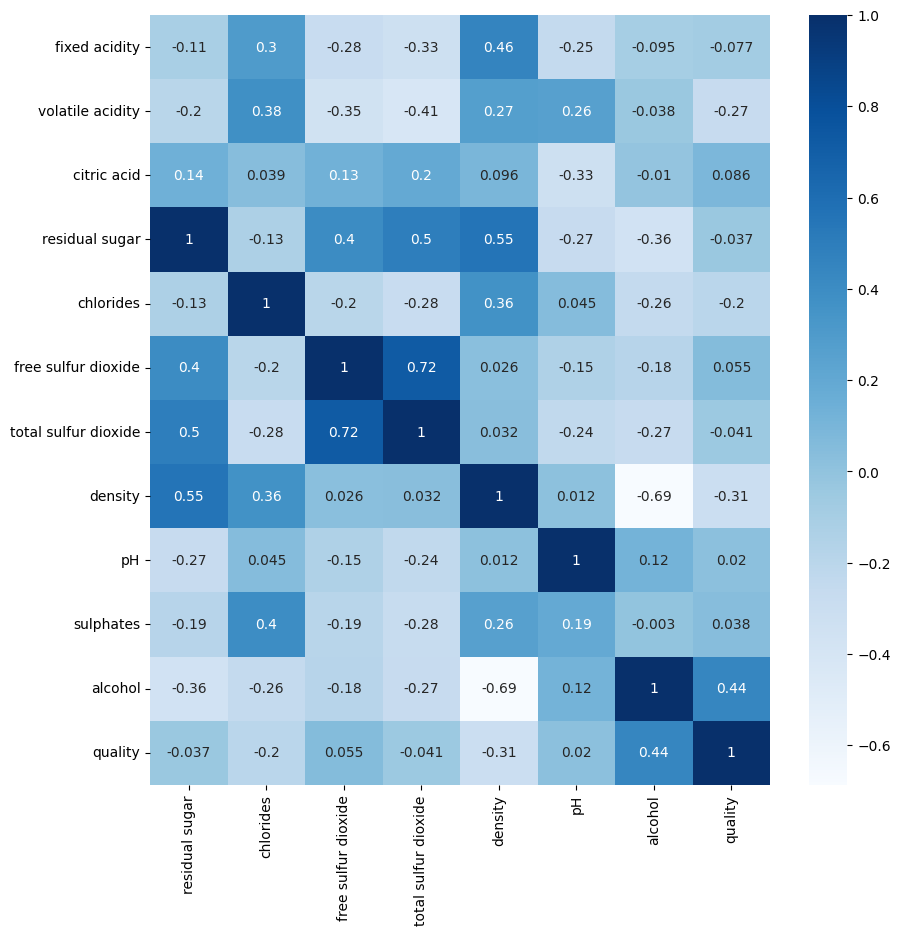

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10,10))
sns.heatmap(corr[features_num_sel], annot= True, cmap= "Blues")

Y ahora sobre la matriz seleccionaríamos como de primera prioridad las que no estuvieran correlacionadas con otra de mayor correlación con el target. Y las restantes como de segunda prioridad.

El análisis visual de features numéricas en problemas con target numérico debe completarse con una visualización bivariante de diagramas de dispersión de forma que si existen relaciones no lineales podamos también observarlas y tenerlas en consideración.

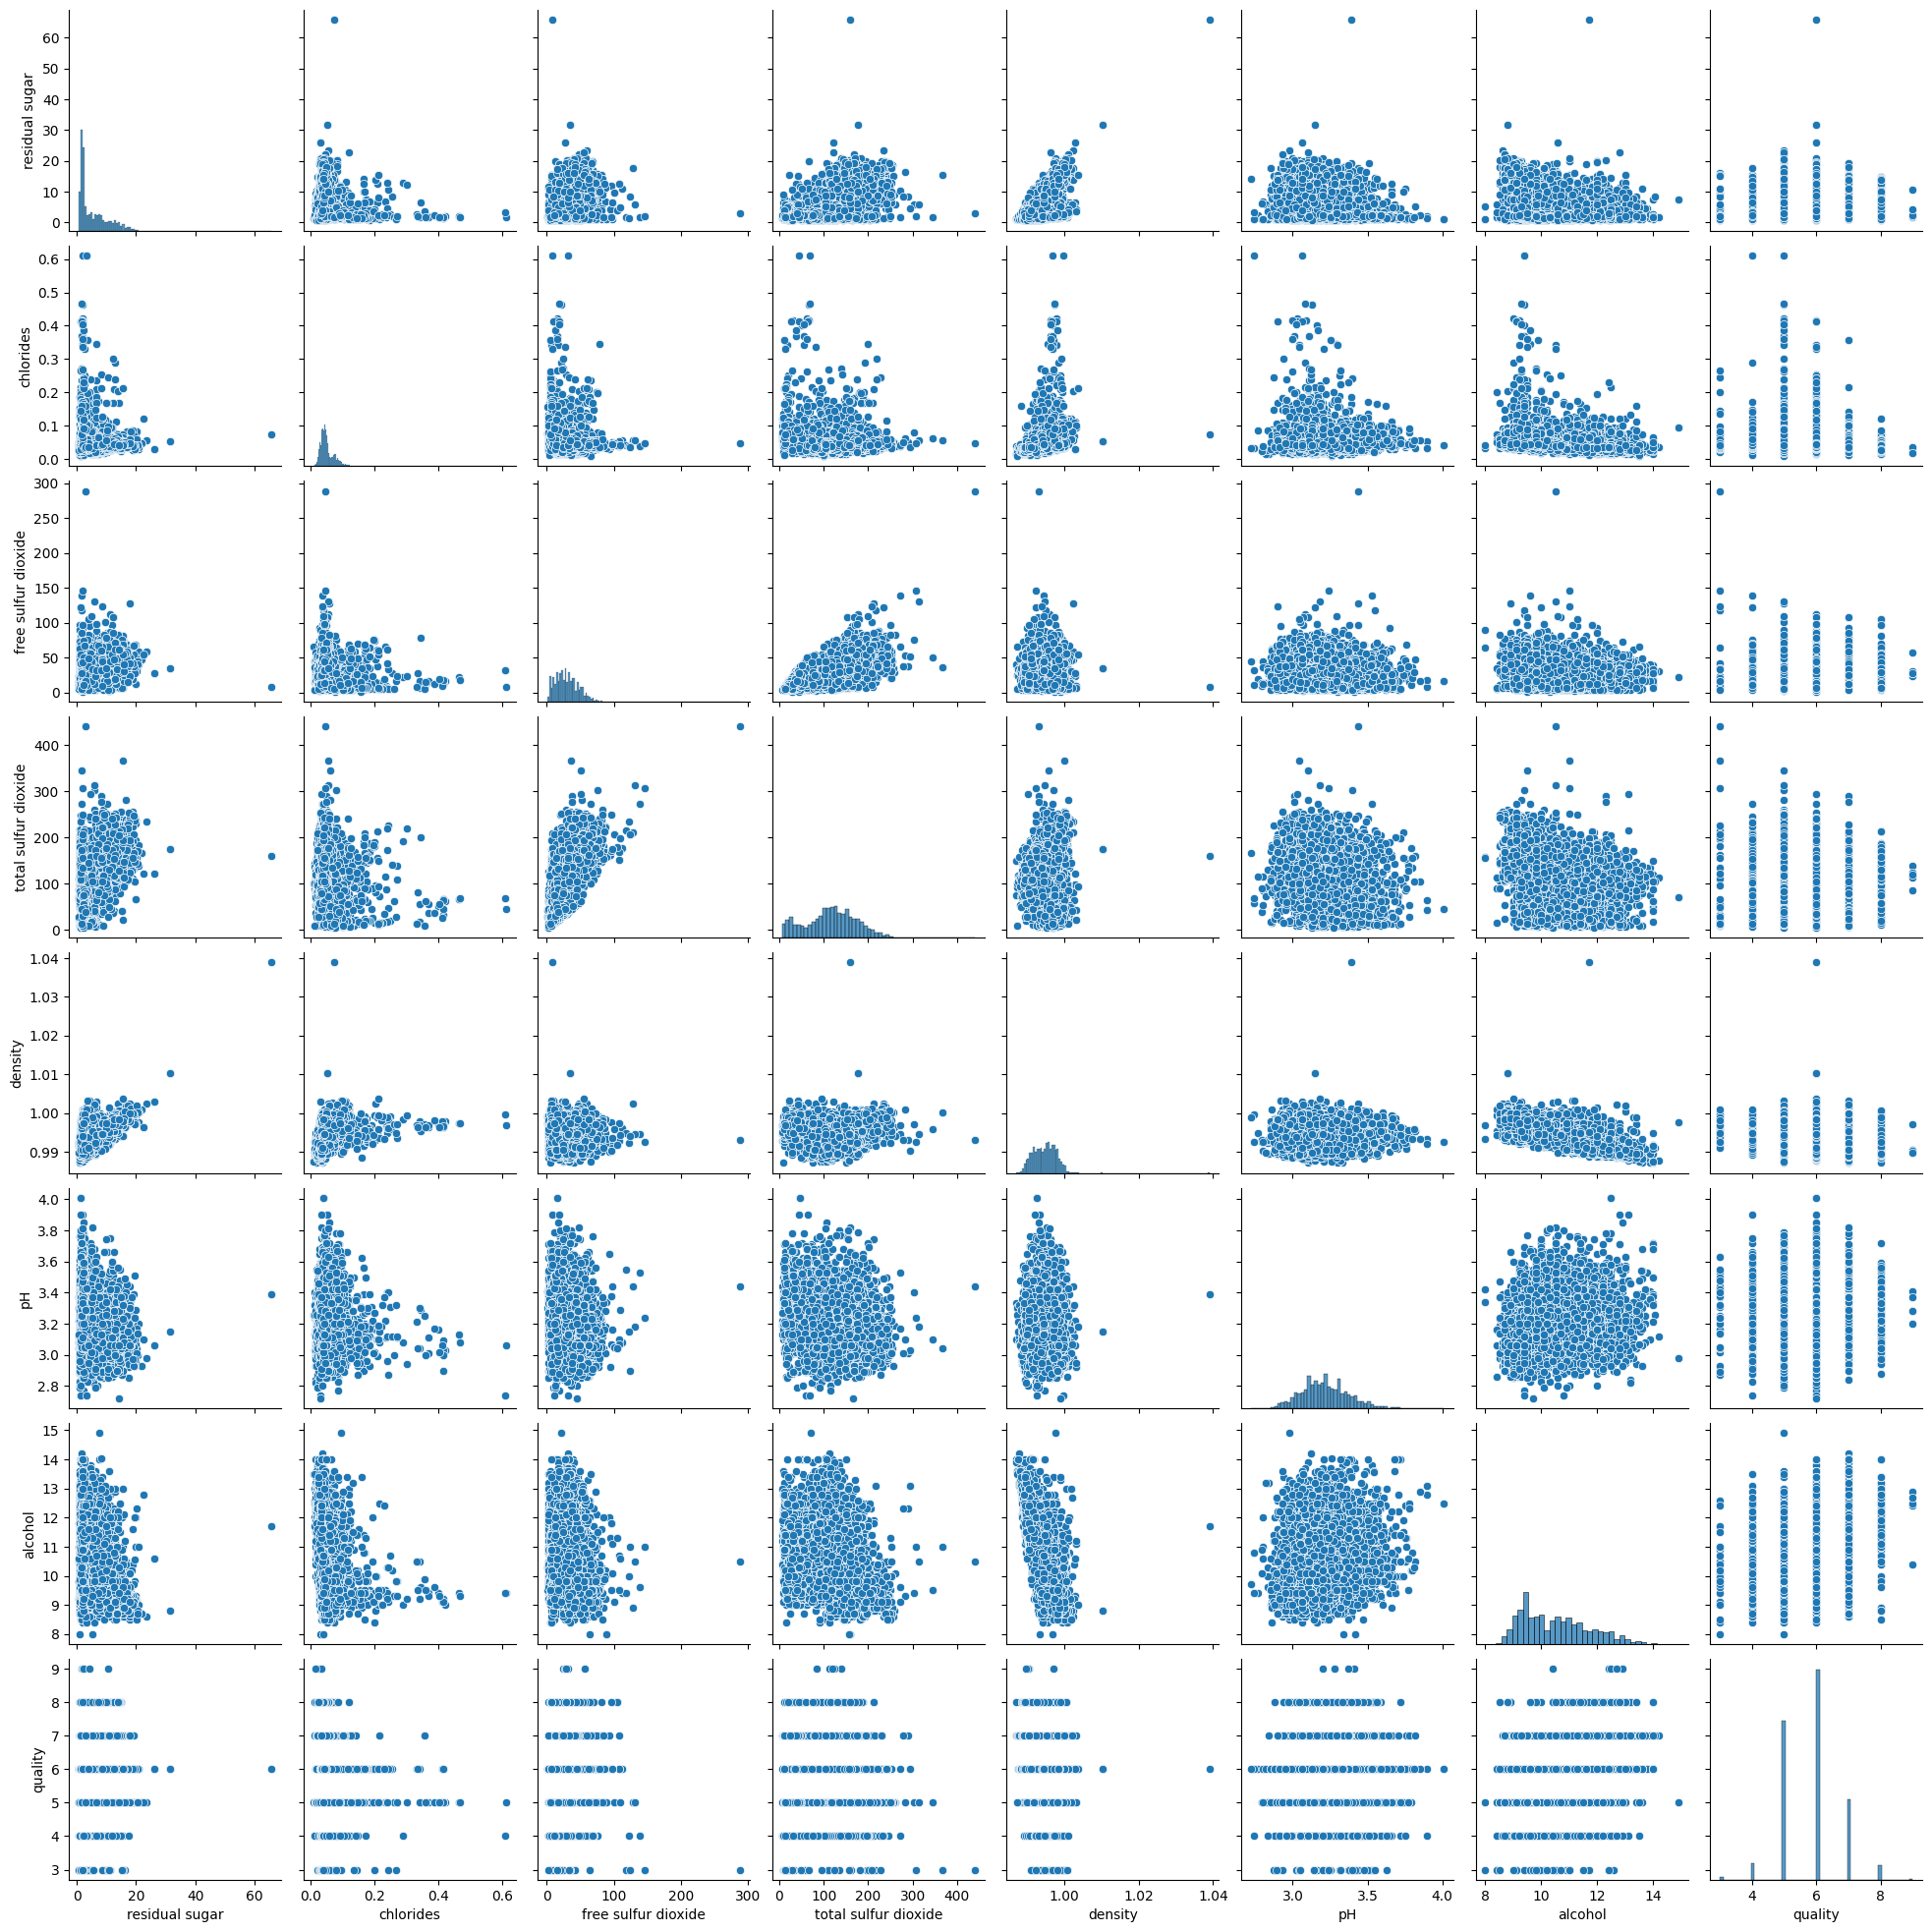

In [13]:
sns.pairplot(df_wines[features_num_sel])

***

### **B. Análisis con datasets supervisados**


#### B.1 Filter (Filtrado): Selección con métricas y tests

En este caso recurrimos a los test y coeficientes que nos dicen si existe relación entre las diferentes features y el target. También se pueden aplicar para ver si existe relación entre las diferentes features entre sí (y evitar efectos tipo colinealidad).

La elección del coeficiente o test depende del tipo de cada variable comparada; una guía de qué usar la tienes en la siguiente figura:

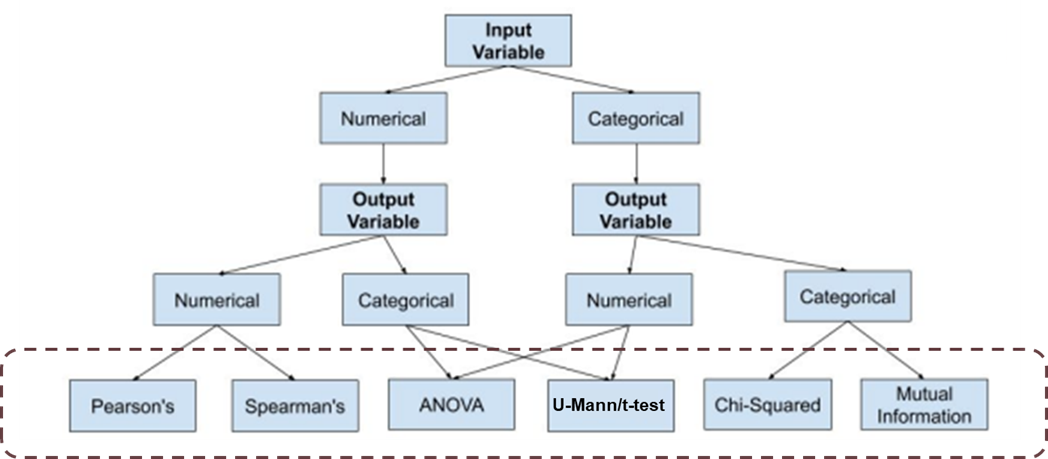

Salvo la correlación de Spearman y el coeficiente de información mutua, el resto son los test que vimos en su momento a la hora de estudiar la relación entre features en el análisis bivariante. En este notebook veremos la Mutual Information: igual que la correlación complementa el análisis visual de los scatter plots, este coeficiente complementa nuestro análisis visual de categóricas con categóricas.

### Cómo usar estas métricas

1. Escoge la adecuada en función del tipo de features que quieras comparar.
2. En el caso de las correlaciones y el Mutual Information puedes poner un umbral (o varios) de superación de la métrica para considerar o agrupar las features por importancia/prioridad (como hemos hecho con la correlación en el análisis visual)
3. En el caso de los test, puedes utilizar el p-value (a menor p-value mejor) para ordenar las features en importancia/prioridad.



#### Mutual Information



Para obtener el coeficiente de Información Mutua (Mutual Information, MI) entre dos variables categóricas en Python, usaremos la función `mutual_info_score` del módulo `sklearn.metrics`. La Información Mutua es una medida de la cantidad de información que una variable contiene sobre otra. En el contexto de variables categóricas, esto puede ayudarte a entender cuánto se puede saber sobre una variable al observar la otra.

Es importante mencionar que la Información Mutua es simétrica: $MI(X;Y) = MI(Y;X)$, lo que significa que el orden de las variables no afecta el resultado.

La Información Mutua es especialmente útil en la selección de características para modelos de aprendizaje automático, ya que permite identificar y seleccionar las características que comparten más información con la variable objetivo, potencialmente mejorando el rendimiento del modelo.

In [14]:
# Volviendo al Titanic
from sklearn.metrics import mutual_info_score
features_cat = ["who","embarked","pclass","alone"]
target = "survived"
df_mi = df.dropna()
for col in features_cat:
    print(f"MI({col};{target}):", mutual_info_score(df_mi[col],df_mi[target]))

MI(who;survived): 0.19164749145327512
MI(embarked;survived): 0.005531414753525178
MI(pclass;survived): 0.0067878230395326325
MI(alone;survived): 0.006223339079755308


La información mutua se interpreta:

- Un valor de $I(X; Y) = 0$ indica que $X$ e $Y$ son completamente independientes, es decir, el conocimiento de $X$ no proporciona ninguna información sobre $Y$, y viceversa.
- Un valor mayor de $I(X; Y)$ indica una mayor dependencia o información compartida entre $X$ e $Y$.



#### Pearson y Spearman

Para obtener una correlación entre dos series de datos en Python, podemos usar Pandas y NumPy, como ya sabes:

**Usando Pandas**

Si tus datos están en estructuras de datos de Pandas (por ejemplo, `Series`), puedes utilizar el método `corr` para calcular la correlación. Pandas soporta varios métodos de correlación como Pearson (por defecto), Spearman y Kendall.


In [15]:

# Crear dos series de datos
serie1 = pd.Series([1, 2, 3, 4, 5])
serie2 = pd.Series([5, 4, 3, 2, 1])

# Calcular la correlación de Pearson
correlacion_pearson = serie1.corr(serie2)
print(f"Correlación de Pearson: {correlacion_pearson}")

# Para calcular la correlación de Spearman o Kendall, especifica el método
correlacion_spearman = serie1.corr(serie2, method='spearman')
print(f"Correlación de Spearman: {correlacion_spearman}")


Correlación de Pearson: -0.9999999999999999
Correlación de Spearman: -0.9999999999999999



**Usando NumPy**

NumPy no tiene una función directa para calcular correlaciones entre dos series, pero puedes calcular el coeficiente de correlación de Pearson usando `numpy.corrcoef`, que devuelve la matriz de correlación.


In [16]:

import numpy as np

# Arrays de datos
datos1 = np.array([1, 2, 3, 4, 5])
datos2 = np.array([5, 4, 3, 2, 1])

# Calcular la matriz de correlación
matriz_correlacion = np.corrcoef(datos1, datos2)

# El coeficiente de correlación de Pearson está en la posición [0, 1] y [1, 0]
print(f"Correlación de Pearson: {matriz_correlacion[0, 1]}")
print(matriz_correlacion)



Correlación de Pearson: -0.9999999999999999
[[ 1. -1.]
 [-1.  1.]]


Te recuerdo aquí cómo hacer el test de significación de la correlación de Pearson, acudiendo a Scipy:

In [17]:
from scipy.stats import pearsonr

pearsonr(df_wines["alcohol"], df_wines["density"])

PearsonRResult(statistic=-0.6867454216821349, pvalue=0.0)

Si el p-value está por debajo del nivel de significación deseado (α, normalmente 0,05), rechazamos la hipótesis nula y podemos aceptar la hipótesis alternativa de que existe una correlación significativa entre las features. En este ejemplo el p-value es prácticamente 0, así que la correlación es claramente significativa.

#### Categórica (no binaria y binaria)-Numérica: ANOVA

Lo empleamos para contrastar si existe una relación significativa entre una variable numérica y una categórica (cualquiera de ellas puede ser el target o simplemente por ver posible relación entre dos features)

In [18]:
from scipy import stats

In [19]:
cat_col = "quality"
quality_cat = df_wines[cat_col].unique()  # Obtener los valores únicos de la columna categórica, en este caso la calidad
alcohol_por_quality = [df_wines[df_wines[cat_col] == categoria]['alcohol'] for categoria in quality_cat] # obtenemos el alcohol de los vinos de cada calidad y los incluimos en una lista

In [20]:
f_val, p_val = stats.f_oneway(*alcohol_por_quality) # El operador * (igual que cuando vimos *args hace mil años) 
                                                    # lo que hace es separar todos los elementos de la lista y pasárselos como argumento a la función
print("Valor F:", f_val)
print("Valor p:", p_val)


Valor F: 320.5934478029265
Valor p: 0.0


Si el p-value está por debajo del nivel de significación deseado (α, normalmente 0,05), rechazamos la hipótesis nula y podemos aceptar la hipótesis alternativa de que existe relación entre las variables a ese nivel de significación.

A partir de aquí, para los métodos de selección supervisados vamos a plantear un problema de clasificación con algo más de miga que distinguir tintos de blancos (eso se consigue casi con cualquier variable, así que cualquier selección acertaría): predecir si un vino es de **calidad alta** (`quality` ≥ 7, en torno al 20% de los vinos) a partir de sus características fisicoquímicas y de su tipo (tinto o blanco). Obviamente, `quality` deja de ser una feature, porque de ella sale el target.

In [21]:
df_wines["calidad_alta"] = (df_wines["quality"] >= 7).astype(int)
df_wines["is_red"] = (df_wines["class"] == "red").astype(int)

features_vino = [col for col in df_wines.columns if col not in ["quality", "class", "calidad_alta"]]
X_train = df_wines[features_vino]
y_train = df_wines["calidad_alta"]

print(len(features_vino), "features:", features_vino)
y_train.value_counts(normalize = True)

12 features: ['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol', 'is_red']


calidad_alta
0    0.803448
1    0.196552
Name: proportion, dtype: float64

Existe una forma de obtener las mejores k variables numéricas en función de su **ANOVA con un target categórico**:

In [22]:
from sklearn.feature_selection import SelectKBest, f_classif

'''
f_classif realiza un test ANOVA.
La técnica de análisis de varianza (ANOVA), desarrollada por Fisher en los años 20 del siglo pasado,
es la herramienta básica para estudiar el efecto de uno o más factores (cada uno con dos o más niveles) sobre
la media de una variable continua. Es, por tanto, el test estadístico a emplear cuando se desea comparar las medias de
dos o más grupos.
'''
selector = SelectKBest(f_classif, k = 6)
x_data_kbest = selector.fit_transform(X_train, y_train)
X_train_kbest = pd.DataFrame(x_data_kbest, columns = selector.get_feature_names_out())
X_train_kbest

,volatile acidity,residual sugar,chlorides,density,alcohol,is_red
0,0.21,9.25,0.034,0.99450,11.4,0.0
1,0.16,7.90,0.025,0.99306,11.9,0.0
2,0.18,1.40,0.038,0.99180,11.2,0.0
3,0.26,2.90,0.047,0.99314,10.5,0.0
4,0.63,2.00,0.083,0.99616,9.8,1.0
...,...,...,...,...,...,...
6492,0.39,10.00,0.056,0.99740,10.2,0.0
6493,0.73,1.70,0.074,0.99680,9.5,1.0
6494,0.31,14.20,0.042,0.99830,9.4,0.0
6495,0.65,2.90,0.089,0.99803,9.5,1.0


#### Categórica (binaria)-Numérica: U de Mann-Whitney

Cuando la categórica es binaria podemos hacer la prueba U para comprobar si existe una relación estadísticamente significativa entre la feature numérica y la categórica:

In [23]:
from scipy.stats import mannwhitneyu
cat_col = "class"
num_col = "alcohol"

grupo_a = df_wines.loc[df_wines[cat_col] == "white"][num_col]
grupo_b = df_wines.loc[df_wines[cat_col] == "red"][num_col]

u_stat, p_valor = mannwhitneyu(grupo_a, grupo_b)

print("Estadístico U:", u_stat)
print("Valor p:", p_valor)

Estadístico U: 4002858.5
Valor p: 0.18184514400050011


Podríamos usar el p-value como indicador de la evidencia de relación: cuanto más bajo, más seguridad de que la relación existe (ojo, eso no quiere decir que la relación sea más fuerte, solo que es más difícil que se deba al azar). En este caso, el p-value de la prueba invita a considerar `class` como una feature predictora de `alcohol`, aunque de segunda prioridad si atendemos a lo que vimos en el análisis visual.

#### Categórica-Categórica (Chi-2 (χ²)):

Además del Mutual Information que acabamos de ver, tenemos el test Chi-2 para evaluar si existe relación entre dos features categóricas:

In [24]:
cat_1 = "pclass"
cat_2 = "who"

#Es necesario obtener la tabla de contingencia (sabemos hacerlo con Pandas):

tabla_contingencia = pd.crosstab(df[cat_1], df[cat_2])

from scipy.stats import chi2_contingency

chi2, p, dof, expected = chi2_contingency(tabla_contingencia)

print("Valor Chi-Cuadrado:", chi2)
print("P-Value:", p)
print("Grados de Libertad:", dof)
print("Tabla de Frecuencias Esperadas:\n", expected)


Valor Chi-Cuadrado: 37.34293526831214
P-Value: 1.5308103860076598e-07
Grados de Libertad: 4
Tabla de Frecuencias Esperadas:
 [[ 20.12121212 130.18181818  65.6969697 ]
 [ 17.14029181 110.8956229   55.9640853 ]
 [ 45.73849607 295.92255892 149.33894501]]


En este caso la relación tiene una clara significación estadística. 

***

#### B.2 Intrinsic: Selección mediante un modelo


Otro enfoque es usar algún modelo base para la evaluación de características porque el modelo mostrará claramente la importancia de las características.  

Se suelen usar dos tipos de modelos: alguna composición "rígida" como RandomForest o un modelo lineal con regularización Lasso para que tenga tendencia a neutralizar pesos de características débiles. La lógica es intuitiva: si las características son claramente inútiles en un modelo simple, no es necesario arrastrarlas a uno más complejo.

Importamos los modelos que vamos a usar e instanciamos el Random Forest que nos servirá de selector:

In [25]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

rf_selector = RandomForestClassifier(random_state = 42)

In [26]:
rf_selector.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

In [27]:
pd.Series(rf_selector.feature_importances_, index = features_vino).sort_values(ascending = False)

alcohol                 0.157012
density                 0.118553
volatile acidity        0.090521
chlorides               0.085293
total sulfur dioxide    0.082201
residual sugar          0.081837
sulphates               0.081041
pH                      0.080052
free sulfur dioxide     0.076479
citric acid             0.075519
fixed acidity           0.068967
is_red                  0.002523
dtype: float64

Y empleamos un objeto específico de `sklearn`:

In [28]:
from sklearn.feature_selection import SelectFromModel

In [29]:
selector_model = SelectFromModel(estimator = rf_selector, threshold= "median") # El modelo debe tener un atributo feature_importances_ o un atributo coef_


El argumento `threshold` determina qué features pasan. El estimador (el modelo de referencia) debe poder proporcionar unas importancias a las features. En este caso, "median" implica que solo nos quedamos con las features cuya importancia para el modelo de referencia es superior a la mediana de las importancias (es decir, con la mitad superior). Si no damos ningún valor, el corte es la media.

In [30]:
selector_model.fit(X_train, y_train)

,"estimator estimator: objectThe base estimator from which the transformer is built.This can be both a fitted (if ``prefit`` is set to True)or a non-fitted estimator. The estimator should have a``feature_importances_`` or ``coef_`` attribute after fitting.Otherwise, the ``importance_getter`` parameter should be used.",RandomForestC...ndom_state=42)
,"threshold threshold: str or float, default=NoneThe threshold value to use for feature selection. Features whoseabsolute importance value is greater or equal are kept while the othersare discarded. If ""median"" (resp. ""mean""), then the ``threshold`` valueis the median (resp. the mean) of the feature importances. A scalingfactor (e.g., ""1.25*mean"") may also be used. If None and if theestimator has a parameter penalty set to l1, either explicitlyor implicitly (e.g, Lasso), the threshold used is 1e-5.Otherwise, ""mean"" is used by default.",'median'
,"prefit prefit: bool, default=FalseWhether a prefit model is expected to be passed into the constructordirectly or not.If `True`, `estimator` must be a fitted estimator.If `False`, `estimator` is fitted and updated by calling`fit` and `partial_fit`, respectively.",False
,"norm_order norm_order: non-zero int, inf, -inf, default=1Order of the norm used to filter the vectors of coefficients below``threshold`` in the case where the ``coef_`` attribute of theestimator is of dimension 2.",1
,"max_features max_features: int, callable, default=NoneThe maximum number of features to select.- If an integer, then it specifies the maximum number of features to allow.- If a callable, then it specifies how to calculate the maximum number of features allowed. The callable will receive `X` as input: `max_features(X)`.- If `None`, then all features are kept.To only select based on ``max_features``, set ``threshold=-np.inf``... versionadded:: 0.20.. versionchanged:: 1.1 `max_features` accepts a callable.",None
,"importance_getter importance_getter: str or callable, default='auto'If 'auto', uses the feature importance either through a ``coef_``attribute or ``feature_importances_`` attribute of estimator.Also accepts a string that specifies an attribute name/pathfor extracting feature importance (implemented with `attrgetter`).For example, give `regressor_.coef_` in case of:class:`~sklearn.compose.TransformedTargetRegressor` or`named_steps.clf.feature_importances_` in case of:class:`~sklearn.pipeline.Pipeline` with its last step named `clf`.If `callable`, overrides the default feature importance getter.The callable is passed with the fitted estimator and it shouldreturn importance for each feature... versionadded:: 0.24",'auto'
Name,Type,Value
"estimator_ estimator_: estimatorThe base estimator from which the transformer is built. This attributeexist only when `fit` has been called.- If `prefit=True`, it is a deep copy of `estimator`.- If `prefit=False`, it is a clone of `estimator` and fit on the data passed to `fit` or `partial_fit`.",RandomForestClassifier,RandomForestC...ndom_state=42)
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](12,)","['fixed acidity','volatile acidity','citric acid',...,'sulphates', 'alcohol','is_red']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 0.24,int,12
threshold_ threshold_: floatThe threshold value used for feature selection.,float64,0.08144


In [31]:
selector_model.get_feature_names_out()

array(['volatile acidity', 'residual sugar', 'chlorides',
       'total sulfur dioxide', 'density', 'alcohol'], dtype=object)

In [32]:
X_train_model = pd.DataFrame(selector_model.transform(X_train), columns = selector_model.get_feature_names_out())
X_train_model

,volatile acidity,residual sugar,chlorides,total sulfur dioxide,density,alcohol
0,0.21,9.25,0.034,142.0,0.99450,11.4
1,0.16,7.90,0.025,107.0,0.99306,11.9
2,0.18,1.40,0.038,111.0,0.99180,11.2
3,0.26,2.90,0.047,440.0,0.99314,10.5
4,0.63,2.00,0.083,91.0,0.99616,9.8
...,...,...,...,...,...,...
6492,0.39,10.00,0.056,178.0,0.99740,10.2
6493,0.73,1.70,0.074,13.0,0.99680,9.5
6494,0.31,14.20,0.042,204.0,0.99830,9.4
6495,0.65,2.90,0.089,40.0,0.99803,9.5


Comparemos ahora una regresión logística entrenada con todas las features con las entrenadas con las features seleccionadas por ANOVA y por el Random Forest.

Ojo a un detalle importante: si seleccionamos las features con todo el train y después hacemos la validación cruzada sobre esas columnas, el selector ya ha "visto" los datos de validación de cada fold y el resultado sale optimista. Lo correcto es meter el selector dentro de un `Pipeline`, junto al escalado y al modelo, para que se reajuste en cada fold:

In [33]:
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

modelo_lr = LogisticRegression(max_iter = 1000, class_weight = "balanced")

pipelines = {
    "Todas las features": Pipeline([("escalado", StandardScaler()), ("modelo", modelo_lr)]),
    "Seleccionadas por ANOVA (k = 6)": Pipeline([("escalado", StandardScaler()),
                                                 ("selector", SelectKBest(f_classif, k = 6)),
                                                 ("modelo", modelo_lr)]),
    "Seleccionadas por Random Forest": Pipeline([("escalado", StandardScaler()),
                                                 ("selector", SelectFromModel(RandomForestClassifier(random_state = 42), threshold = "median")),
                                                 ("modelo", modelo_lr)]),
}

for nombre, pipeline in pipelines.items():
    score = np.mean(cross_val_score(pipeline, X_train, y_train, cv = 5, scoring = "balanced_accuracy", n_jobs = -1))
    print(f"{nombre}: balanced accuracy = {score:.3f}")

Todas las features: balanced accuracy = 0.739


Seleccionadas por ANOVA (k = 6): balanced accuracy = 0.736


Seleccionadas por Random Forest: balanced accuracy = 0.734


Las tres opciones quedan prácticamente empatadas (0,739 con las 12 features frente a 0,736 y 0,734 con 6): seleccionar la mitad de las features apenas cuesta rendimiento. Es lo habitual con pocas features y casi todas informativas: la selección no mejora la métrica, pero nos da un modelo más simple a un coste muy bajo, y ese compromiso es el que tenemos que valorar.

En lugar del Random Forest, podríamos haber usado cualquier modelo que permita obtener coeficientes o importancias.

***

#### B.3 Wrapper

Este tipo de mecanismos se basan en ir quitando o sumando features hasta alcanzar un umbral en una métrica de selección (normalmente la métrica que usaríamos en el problema a resolver con el modelo que estemos buscando) o conseguir pocas variaciones por debajo o por encima del mismo o alcanzar un número de features determinado por el usuario (o sea, nosotros).  

Veremos dos aproximaciones:
1. Partir de todas las features e ir entrenando modelos quitando cada vez la feature con menor peso hasta llegar a la condición de parada.  
2. Partir de una feature e ir añadiendo features hasta alcanzar la condición de parada.

#### Eliminación recursiva de features

Se escoge un estimador o modelo y un número n de features. Se entrena el estimador con TODAS las features y se calcula la importancia (`feature_importances_` o `coef_`) de cada una. La peor feature se elimina y se entrena otro modelo con una feature menos, y así hasta llegar a n.

Puedes verlo como una versión iterativa de la selección por modelo, en la que no haces un único corte sino que vas haciendo cortes sucesivos para así captar los posibles cambios en las importancias de las features al tener cada vez menos.

En sklearn se implementa con `RFE` (Recursive Feature Elimination) y necesita un modelo que tenga o bien el atributo `feature_importances_` o bien `coef_`.

In [34]:
from sklearn.feature_selection import RFE

In [35]:
rf_RFE = RandomForestClassifier(random_state = 42) # Puedes usar tu modelo, o modelos a probar o un modelo "proxy" como en la selección por modelo

rfe = RFE(estimator = rf_RFE,
          n_features_to_select = 6, # Iterará hasta quedarse con 6
          step = 1) # Elimina de una en una, pero es configurable

rfe.fit(X_train, y_train)
pd.DataFrame(rfe.ranking_, columns = ["ranking"], index = features_vino).sort_values("ranking")

,ranking
volatile acidity,1
residual sugar,1
total sulfur dioxide,1
density,1
pH,1
alcohol,1
chlorides,2
sulphates,3
free sulfur dioxide,4
citric acid,5


Podemos compararlas con las features obtenidas con otros selectores:

In [36]:
print("Seleccionadas por modelo:", list(selector_model.get_feature_names_out()))

Seleccionadas por modelo: ['volatile acidity', 'residual sugar', 'chlorides', 'total sulfur dioxide', 'density', 'alcohol']


In [37]:
print("Seleccionadas por ANOVA:", X_train_kbest.columns.to_list())

Seleccionadas por ANOVA: ['volatile acidity', 'residual sugar', 'chlorides', 'density', 'alcohol', 'is_red']


¿Y con cuál me quedo? Lo hablaremos al final. Pero antes, observa que RFE no usa ninguna métrica para decidir: en cada paso elimina la feature con menor importancia (`feature_importances_`) o menor coeficiente (`coef_`) según el modelo, y ANOVA ni siquiera usa un modelo. Por eso es fácil que salgan selecciones diferentes.

Para terminar este método, el objeto RFE te permite obtener con su método `transform` el dataset solo con las columnas seleccionadas. Eso sí, lo devuelve como un array de NumPy y hay que hacer alguna cosita si queremos convertirlo a DataFrame:

In [38]:
rfe.transform(X_train)

array([[2.1000e-01, 9.2500e+00, 1.4200e+02, 9.9450e-01, 3.0500e+00,
        1.1400e+01],
       [1.6000e-01, 7.9000e+00, 1.0700e+02, 9.9306e-01, 2.9300e+00,
        1.1900e+01],
       [1.8000e-01, 1.4000e+00, 1.1100e+02, 9.9180e-01, 3.3200e+00,
        1.1200e+01],
       ...,
       [3.1000e-01, 1.4200e+01, 2.0400e+02, 9.9830e-01, 3.0600e+00,
        9.4000e+00],
       [6.5000e-01, 2.9000e+00, 4.0000e+01, 9.9803e-01, 3.2900e+00,
        9.5000e+00],
       [6.7000e-01, 2.2000e+00, 7.5000e+01, 9.9736e-01, 3.2000e+00,
        9.2000e+00]])

In [39]:
X_train_rfe_wines = pd.DataFrame(rfe.transform(X_train), columns = rfe.get_feature_names_out())
X_train_rfe_wines

,volatile acidity,residual sugar,total sulfur dioxide,density,pH,alcohol
0,0.21,9.25,142.0,0.99450,3.05,11.4
1,0.16,7.90,107.0,0.99306,2.93,11.9
2,0.18,1.40,111.0,0.99180,3.32,11.2
3,0.26,2.90,440.0,0.99314,3.44,10.5
4,0.63,2.00,91.0,0.99616,3.26,9.8
...,...,...,...,...,...,...
6492,0.39,10.00,178.0,0.99740,3.26,10.2
6493,0.73,1.70,13.0,0.99680,3.20,9.5
6494,0.31,14.20,204.0,0.99830,3.06,9.4
6495,0.65,2.90,40.0,0.99803,3.29,9.5


#### Selección secuencial de Features

En este caso empezamos con una feature y vamos añadiendo hasta llegar a un límite de features o bien hasta alcanzar un umbral o valor que no varía excesivamente (tendremos que tener una tolerancia).

En general funciona así:
1. Se entrena un modelo para cada feature con esa feature como predictora. Nos quedamos con la feature que consiga el mejor modelo (tendremos que seleccionar una métrica).
2. Se entrena un modelo para cada combinación de la feature escogida y el resto de features. Nos quedamos con la mejor combinación.
3. Se repite 2 hasta llegar a la condición de parada.

Por supuesto, en `sklearn` tenemos una clase para hacerlo: `SequentialFeatureSelector`, que tiene la ventaja de que puede aplicarse aunque el modelo guía no tenga ni `feature_importances_` ni `coef_` entre sus atributos.

In [40]:
from sklearn.feature_selection import SequentialFeatureSelector

rf_SFS = RandomForestClassifier(random_state = 42)

sfs_forward = SequentialFeatureSelector(rf_SFS,
                                        n_features_to_select = 6,
                                        cv = 4,
                                        scoring = "balanced_accuracy",
                                        n_jobs = -1)

sfs_forward.fit(X_train, y_train)


,estimator estimator: estimator instanceAn unfitted estimator.,RandomForestC...ndom_state=42)
,"n_features_to_select n_features_to_select: ""auto"", int or float, default=""auto""If `""auto""`, the behaviour depends on the `tol` parameter:- if `tol` is not `None`, then features are selected while the score change does not exceed `tol`.- otherwise, half of the features are selected.If integer, the parameter is the absolute number of features to select.If float between 0 and 1, it is the fraction of features to select... versionadded:: 1.1 The option `""auto""` was added in version 1.1... versionchanged:: 1.3 The default changed from `""warn""` to `""auto""` in 1.3.",6
,"scoring scoring: str or callable, default=NoneScoring method to use for cross-validation. Options:- str: see :ref:`scoring_string_names` for options.- callable: a scorer callable object (e.g., function) with signature ``scorer(estimator, X, y)`` that returns a single value. See :ref:`scoring_callable` for details.- `None`: the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.",'balanced_accuracy'
,"cv cv: int, cross-validation generator or an iterable, default=5Determines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass,:class:`~sklearn.model_selection.StratifiedKFold` is used. In all othercases, :class:`~sklearn.model_selection.KFold` is used. These splittersare instantiated with `shuffle=False` so the splits will be the sameacross calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here.",4
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel. When evaluating a new feature toadd or remove, the cross-validation procedure is parallel over thefolds.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",-1
,"tol tol: float, default=NoneIf the score is not incremented by at least `tol` between twoconsecutive feature additions or removals, stop adding or removing.`tol` can be negative when removing features using `direction=""backward""`.`tol` is required to be strictly positive when doing forward selection.It can be useful to reduce the number of features at the cost of a smalldecrease in the score.`tol` is enabled only when `n_features_to_select` is `""auto""`... versionadded:: 1.1",None
,"direction direction: {'forward', 'backward'}, default='forward'Whether to perform forward selection or backward selection.",'forward'
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](12,)","['fixed acidity','volatile acidity','citric acid',...,'sulphates', 'alcohol','is_red']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 0.24,int,12
n_features_to_select_ n_features_to_select_: intThe number of features that were selected.,int32,6


Observa los tiempos de ejecución: SFS entrena muchísimos modelos (en cada paso, uno por cada feature candidata y por cada fold). Eso sí, es un algoritmo voraz (*greedy*): en cada paso se queda con la mejor feature y ya no la cuestiona, así que no prueba todas las combinaciones posibles (eso sería inabordable). Por otro lado, las elegidas aquí no tienen ranking:

In [41]:
print("Elegidas por SFS:", list(sfs_forward.get_feature_names_out()))

Elegidas por SFS: ['citric acid', 'residual sugar', 'density', 'pH', 'sulphates', 'alcohol']


Y de nuevo es diferente la selección. Hmmm, qué interesante. 

***

### **Cuando la selección sí marca la diferencia: features de ruido**

Hasta ahora, seleccionar features apenas ha cambiado (o incluso ha empeorado ligeramente) el rendimiento. Es lo normal cuando tenemos pocas features y casi todas aportan algo. Veamos qué pasa cuando hay features que no aportan nada: vamos a añadir 30 columnas de ruido aleatorio (en un caso real podrían ser columnas irrelevantes, códigos o identificadores mal tratados, variables mal recogidas...).

In [42]:
rng = np.random.default_rng(42)
ruido = pd.DataFrame(rng.normal(size = (len(X_train), 30)), columns = [f"ruido_{i}" for i in range(30)], index = X_train.index)

X_train_ruido = pd.concat([X_train, ruido], axis = 1)
X_train_ruido.shape

(6497, 42)

In [43]:
rf_modelo = RandomForestClassifier(random_state = 42, class_weight = "balanced")

comparativa = {
    "Features originales": (Pipeline([("modelo", rf_modelo)]), X_train),
    "Originales + 30 de ruido": (Pipeline([("modelo", rf_modelo)]), X_train_ruido),
    "Ruido + selección ANOVA (k = 12)": (Pipeline([("selector", SelectKBest(f_classif, k = 12)), ("modelo", rf_modelo)]), X_train_ruido),
}

for nombre, (pipeline, X) in comparativa.items():
    score = np.mean(cross_val_score(pipeline, X, y_train, cv = 5, scoring = "balanced_accuracy", n_jobs = -1))
    print(f"{nombre} ({X.shape[1]} features): balanced accuracy = {score:.3f}")

Features originales (12 features): balanced accuracy = 0.817


Originales + 30 de ruido (42 features): balanced accuracy = 0.725


Ruido + selección ANOVA (k = 12) (42 features): balanced accuracy = 0.805


Con 30 columnas de ruido, el Random Forest pasa de 0,817 a 0,725: el ruido le hace daño, porque algunos árboles acaban usándolo para dividir. Si metemos una selección por ANOVA en el pipeline, recupera casi todo el rendimiento (0,805). Aquí la selección sí marca la diferencia en la métrica. Veamos qué columnas ha elegido ANOVA:

In [44]:
selector_ruido = SelectKBest(f_classif, k = 12).fit(X_train_ruido, y_train)
seleccionadas = selector_ruido.get_feature_names_out()
print("Columnas de ruido entre las 12 seleccionadas:", [col for col in seleccionadas if col.startswith("ruido")])

Columnas de ruido entre las 12 seleccionadas: ['ruido_15']


De las 30 columnas de ruido solo se ha colado una entre las 12 seleccionadas. Moraleja: cuando sospeches que hay features irrelevantes (y en datasets reales con muchas columnas es lo normal), la selección es imprescindible; cuando todas aportan, es sobre todo una cuestión de simplicidad.

***

### **C. Análisis con métodos no supervisados**

Vamos a "ver" dos mecanismos que puedes aplicar a un dataset independientemente de si tiene target o no (de ahí lo de no supervisados):

1. PCA (Análisis de Componentes Principales)
2. Umbral de Varianza

#### PCA

No vamos a repetir lo que ya hemos visto, solo a repasar los pasos para obtener las componentes principales (PCs) y luego hacer selección:
1. Obtener todas las PCs (usando sklearn).
2. Analizar la proporción acumulada de varianza y escoger un umbral mínimo.
3. Escoger las PCs según ese umbral.
4. Trabajar con el dataset transformado (es decir, usando el resultado de aplicar las PCs de 3).

Recuerda además que, antes de aplicarla, hay que escalar las features.

$$*$$

#### Umbral de Varianza

Es el mecanismo más sencillo y se basa en la idea de que las features que varían poco tienen poca información (al igual que las que son diferentes para todas las instancias).

Basado en lo anterior, escogemos un umbral de varianza mínima y seleccionamos aquellas features cuya varianza esté por encima:

In [45]:
from sklearn.feature_selection import VarianceThreshold

umbral_varianza = 0.5

var_selector = VarianceThreshold(umbral_varianza)
var_selector.fit(X_train)
print("Lista seleccionada para selector de Varianza", var_selector.get_feature_names_out())

Lista seleccionada para selector de Varianza ['fixed acidity' 'residual sugar' 'free sulfur dioxide'
 'total sulfur dioxide' 'alcohol']


Ojo: fíjate en que se queda con las variables de mayor escala (los sulfuros, que se miden en mg/l y toman valores de decenas o cientos, el azúcar residual, la acidez fija o el alcohol), no necesariamente con las más informativas. La varianza depende de las unidades, así que este selector solo tiene sentido con variables en escalas comparables o, con un umbral muy bajo, para eliminar variables constantes o casi constantes.

Y, como todos los transformadores de `sklearn`, permite obtener el array transformado, es decir, solo con las features seleccionadas:

In [46]:
X_train_var = var_selector.transform(X_train)
X_train_var

array([[  8.5 ,   9.25,  73.  , 142.  ,  11.4 ],
       [  8.3 ,   7.9 ,  38.  , 107.  ,  11.9 ],
       [  6.8 ,   1.4 ,  35.  , 111.  ,  11.2 ],
       ...,
       [  7.4 ,  14.2 ,  62.  , 204.  ,   9.4 ],
       [  8.3 ,   2.9 ,  17.  ,  40.  ,   9.5 ],
       [  8.4 ,   2.2 ,  11.  ,  75.  ,   9.2 ]])

In [47]:
X_train_var = pd.DataFrame(var_selector.transform(X_train), columns = var_selector.get_feature_names_out())
X_train_var

,fixed acidity,residual sugar,free sulfur dioxide,total sulfur dioxide,alcohol
0,8.5,9.25,73.0,142.0,11.4
1,8.3,7.90,38.0,107.0,11.9
2,6.8,1.40,35.0,111.0,11.2
3,6.1,2.90,289.0,440.0,10.5
4,7.5,2.00,17.0,91.0,9.8
...,...,...,...,...,...
6492,7.7,10.00,35.0,178.0,10.2
6493,8.2,1.70,5.0,13.0,9.5
6494,7.4,14.20,62.0,204.0,9.4
6495,8.3,2.90,17.0,40.0,9.5


Observa que no necesitamos un target para nada, con lo que es posible aplicarlo en cualquier dataset. Lo útil o no que sea depende del problema y contexto. 

### **A MODO DE GUÍA**

Para terminar, y solo como una guía y no unos mandamientos, te dejo aquí algunas sugerencias:

1. MiniEDA: Haz siempre que puedas un análisis visual, aunque sea después de una selección inicial si son demasiadas features.
2. Si puedes: no descartes, crea listas con diferente nivel de prioridad y haz "selección de listas".
3. Mecanismos basados en test: Utiliza p-value para ordenar (de menor a mayor p-value) las features. Selecciona las n mejores (n lo tendrás que poner tú, que algo tendrás que hacer, vamos, digo yo).
4. Aplica todos los mecanismos que creas conveniente (aunque algunos podrás y otros no según el contexto). Recuerda: PCA transforma y para luego explicar hay que acudir a las relaciones de cada PCA con las features originales (que es farragoso pero se puede hacer). 
5. Si aplicas varios mecanismos, ¿con cuál me quedo?
    5.1 En caso supervisado: puedes entrenar cada selección por separado y quedarte con la que mejor score te dé en la validación cruzada (metiendo el selector en un `Pipeline` para que la comparación sea justa). Y no te quedes solo con la métrica: si una selección con muchas menos features pierde muy poco, puede ser la mejor opción.  
    5.2 Puedes implementar un mecanismo de voting. Por ejemplo, por cada método que seleccione una feature le das un voto, y al final te quedas con las más votadas.  
    5.3 Sé creativo   
    

Para terminar...

DALE LA VUELTA (para todos aquellos que pensáis que el EDA se terminó presentando el proyecto): Usa el ML para analizar las variables y aplicarlo a tus EDAs. Una parte importante de un EDA, si no la que más, es el análisis multivariante, y los modelos, en el fondo, nos dicen si hay relación entre las variables. Prueba a predecir cada variable de tu EDA a partir del resto (es decir, a buscar su relación con las demás) y enriquecerás tu análisis de forma asombrosa...